## 1. Configuração do experimento

In [ ]:
"""
Letra b) — Regressao com MLP no Diabetes Dataset do Scikit-Learn.

Dependencias:
    pip install numpy matplotlib scikit-learn torch

O conjunto possui 442 amostras, 10 atributos preditores e um alvo quantitativo.
A divisão é 70% treino, 15% validação e 15% teste.
O conjunto de teste não participa do treinamento nem da seleção da melhor época.
"""
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

## 2. Carregamento e estatísticas iniciais

In [ ]:
# 1) Carregamento — linhas solicitadas no enunciado
diabetes = load_diabetes()
print("Primeiros três valores do alvo:", diabetes.target[:3])
print("Formato da matriz de atributos:", diabetes.data.shape)

X = diabetes.data.astype(np.float32)                  # 442 x 10
y = diabetes.target.astype(np.float32).reshape(-1, 1) # alvo quantitativo
print("Atributos:", diabetes.feature_names)
print("Média do alvo:", y.mean())
print("Desvio padrão do alvo:", y.std())
print("Mínimo e máximo do alvo:", y.min(), y.max())

Primeiros três valores do alvo: [151.  75. 141.]
Formato da matriz de atributos: (442, 10)
Atributos: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Média do alvo: 152.13348
Desvio padrão do alvo: 77.005745
Mínimo e máximo do alvo: 25.0 346.0


## 3. Análise exploratória: ausências, duplicatas, distribuições e correlações
Verificam-se **ausências**, **duplicatas**, distribuições dos atributos e **correlações**. Não há imputação a realizar se os dados vierem completos. Correlações são apresentadas para interpretação, e não utilizadas para selecionar atributos com conhecimento prévio do teste.

Ausências por variável:
age           0
sex           0
bmi           0
bp            0
s1            0
s2            0
s3            0
s4            0
s5            0
s6            0
progressao    0
Duplicatas completas: 0
Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
age,442.0,0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,-0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


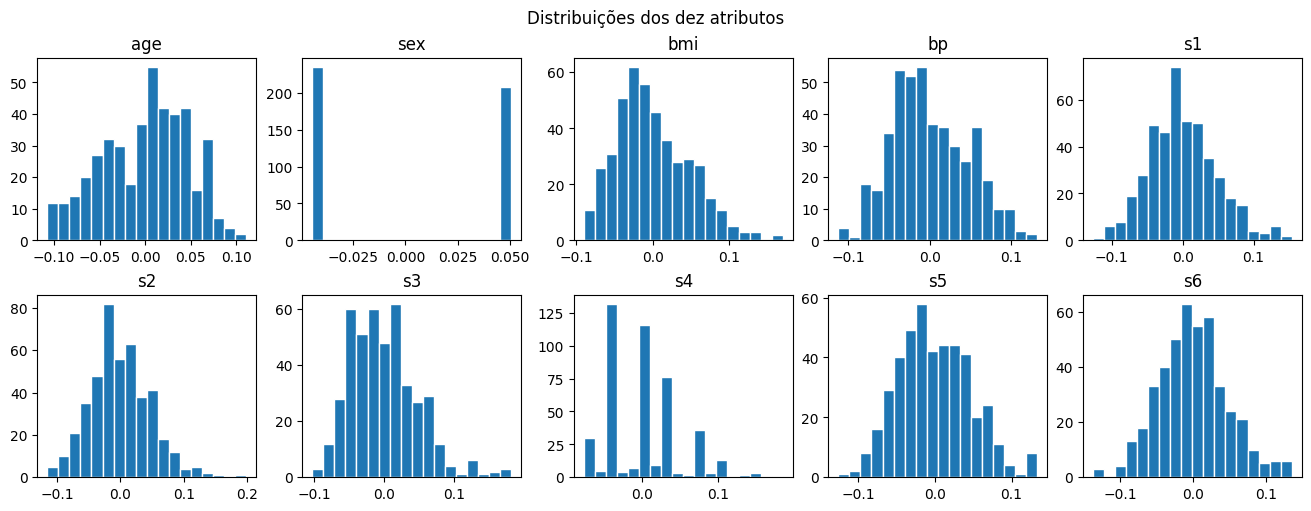

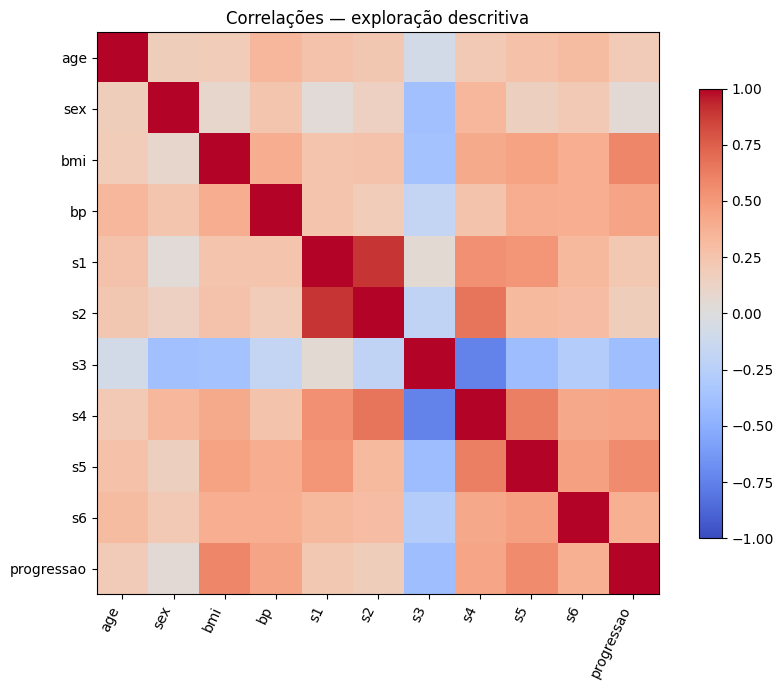

In [ ]:
import pandas as pd
base_eda = pd.DataFrame(X, columns=diabetes.feature_names)
base_eda['progressao'] = y.ravel()
print('Ausências por variável:')
print(base_eda.isna().sum().to_string())
print('Duplicatas completas:', int(base_eda.duplicated().sum()))
print('Estatísticas descritivas:')
display(base_eda.describe().T.round(3))
fig, axs = plt.subplots(2, 5, figsize=(13, 5), constrained_layout=True)
for ax, coluna in zip(axs.flat, diabetes.feature_names):
    ax.hist(base_eda[coluna], bins=18, edgecolor='white')
    ax.set_title(coluna)
fig.suptitle('Distribuições dos dez atributos')
plt.show()
fig, ax = plt.subplots(figsize=(9, 7))
correlacao = base_eda.corr(numeric_only=True)
im = ax.imshow(correlacao, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(correlacao)), correlacao.columns, rotation=65, ha='right')
ax.set_yticks(range(len(correlacao)), correlacao.index)
ax.set_title('Correlações — exploração descritiva')
fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout()
plt.show()
assert not base_eda.isna().any().any(), 'Verificar valores ausentes antes do treino'

## 4. Distribuição do alvo

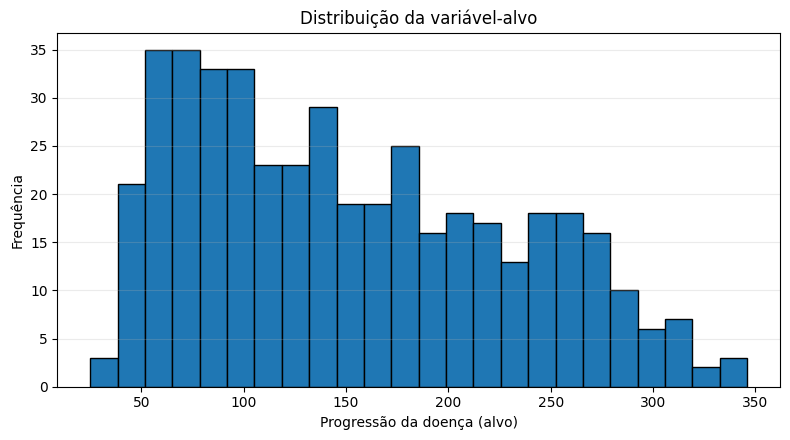

In [ ]:
# 2) Análise exploratória: distribuição do alvo
plt.figure(figsize=(8, 4.5))
plt.hist(y[:, 0], bins=24, edgecolor="black")
plt.xlabel("Progressão da doença (alvo)")
plt.ylabel("Frequência")
plt.title("Distribuição da variável-alvo")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("diabetes_distribuicao_alvo.png", dpi=180)
plt.show()

## 5. Partição de treinamento, validação e teste

In [ ]:
# 3) Separação dos dados: 70% treino, 15% validação e 15% teste
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

## 6. Normalização sem vazamento

In [ ]:
# 4) Normalização sem vazamento: ajustar somente com o treino.
# load_diabetes já fornece atributos transformados, mas padronizamos novamente
# com parâmetros calculados exclusivamente no conjunto de treinamento.
scaler_X = StandardScaler().fit(X_train)
scaler_y = StandardScaler().fit(y_train)

def transformar(a, scaler):
    return torch.tensor(scaler.transform(a), dtype=torch.float32)

Xtr, Ytr = transformar(X_train, scaler_X), transformar(y_train, scaler_y)
Xva, Yva = transformar(X_val, scaler_X), transformar(y_val, scaler_y)

## 7. Arquitetura MLP de regressão

In [ ]:
# 5) Arquitetura MLP: 10 entradas -> 16 neurônios -> 1 saída linear
modelo = nn.Sequential(
    nn.Linear(10, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)
otimizador = torch.optim.Adam(
    modelo.parameters(), lr=0.001, weight_decay=0.01
)
funcao_erro = nn.MSELoss()
lotes = DataLoader(
    TensorDataset(Xtr, Ytr), batch_size=32, shuffle=True
)

## 8. Treinamento com validação e curvas de erro

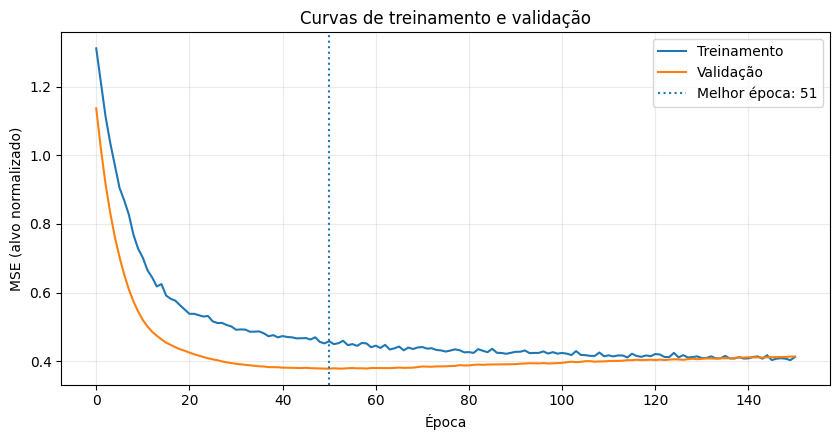

In [ ]:
# 6) Treinamento com acompanhamento da validação e parada antecipada
max_epocas = 1200
paciencia = 100
melhor_validacao = float("inf")
melhor_estado = None
melhor_epoca = 0
espera = 0
erros_treino, erros_validacao = [], []

for epoca in range(max_epocas):
    modelo.train()
    erros_lotes = []
    for xb, yb in lotes:
        otimizador.zero_grad()
        perda = funcao_erro(modelo(xb), yb)
        perda.backward()
        otimizador.step()
        erros_lotes.append(perda.item())

    modelo.eval()
    with torch.no_grad():
        erro_validacao = funcao_erro(modelo(Xva), Yva).item()

    erros_treino.append(float(np.mean(erros_lotes)))
    erros_validacao.append(float(erro_validacao))

    if erro_validacao < melhor_validacao - 1e-6:
        melhor_validacao = erro_validacao
        melhor_estado = {
            k: v.detach().clone() for k, v in modelo.state_dict().items()
        }
        melhor_epoca = epoca + 1
        espera = 0
    else:
        espera += 1

    if espera >= paciencia:
        break

# Recupera os pesos da época com menor erro de validação
modelo.load_state_dict(melhor_estado)
modelo.eval()

# Curvas de erro (MSE na escala normalizada do alvo)
plt.figure(figsize=(8.5, 4.5))
plt.plot(erros_treino, label="Treinamento")
plt.plot(erros_validacao, label="Validação")
plt.axvline(melhor_epoca - 1, linestyle=":", label=f"Melhor época: {melhor_epoca}")
plt.xlabel("Época")
plt.ylabel("MSE (alvo normalizado)")
plt.title("Curvas de treinamento e validação")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("diabetes_curvas_treinamento_validacao.png", dpi=180)
plt.show()

## 9. Métricas no conjunto de teste

In [ ]:
# 7) Avaliação final no conjunto de teste, que ficou separado
with torch.no_grad():
    pred_teste_norm = modelo(transformar(X_test, scaler_X)).numpy()
y_pred = scaler_y.inverse_transform(pred_teste_norm)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Referência simples: prever sempre a média do alvo de treinamento
baseline = np.full_like(y_test, float(y_train.mean()))
rmse_baseline = math.sqrt(mean_squared_error(y_test, baseline))

print(f"Épocas executadas: {len(erros_treino)}")
print(f"Melhor época: {melhor_epoca}")
print(f"MAE no teste:  {mae:.4f}")
print(f"MSE no teste:  {mse:.4f}")
print(f"RMSE no teste: {rmse:.4f}")
print(f"R² no teste:   {r2:.4f}")
print(f"RMSE da referência pela média: {rmse_baseline:.4f}")

Épocas executadas: 151
Melhor época: 51
MAE no teste:  45.8582
MSE no teste:  3068.5981
RMSE no teste: 55.3949
R² no teste:   0.4596
RMSE da referência pela média: 75.5421


## 10. Gráfico de valores reais versus preditos

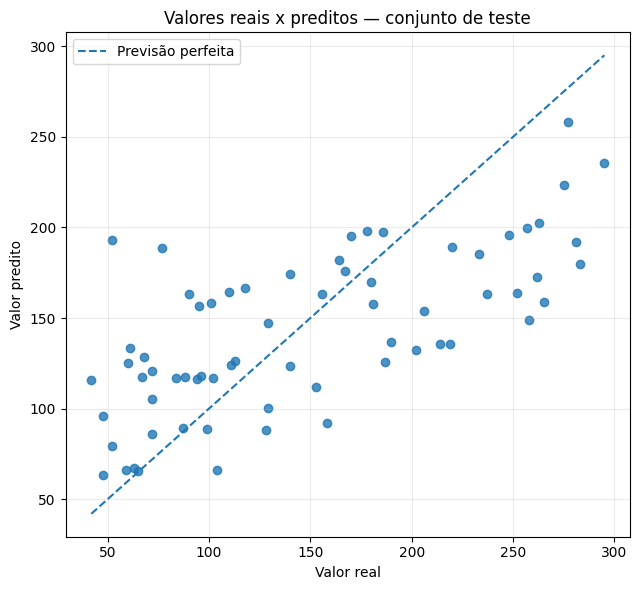

In [ ]:
# 8) Gráfico de valores reais x preditos no teste
limite_min = min(float(y_test.min()), float(y_pred.min()))
limite_max = max(float(y_test.max()), float(y_pred.max()))
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test[:, 0], y_pred[:, 0], alpha=0.8)
plt.plot([limite_min, limite_max], [limite_min, limite_max],
         "--", label="Previsão perfeita")
plt.xlabel("Valor real")
plt.ylabel("Valor predito")
plt.title("Valores reais x preditos — conjunto de teste")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("diabetes_real_vs_predito.png", dpi=180)
plt.show()

## 11. Comparação ordenada dos valores reais e preditos

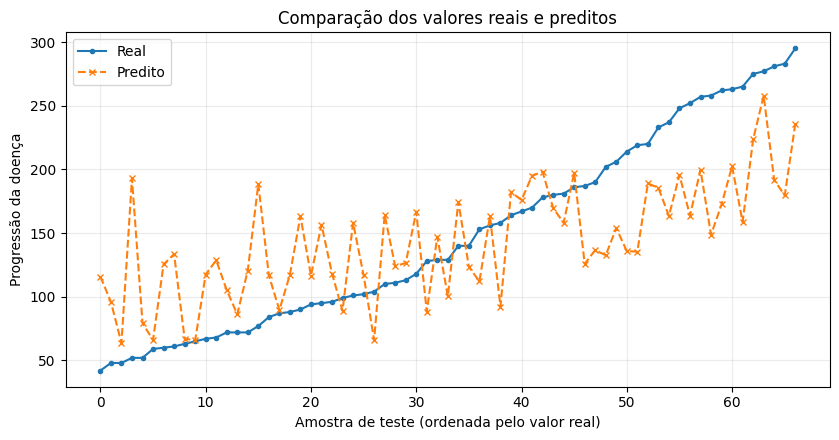

In [ ]:
# 9) Comparação ordenada para facilitar a leitura
ordem = np.argsort(y_test[:, 0])
plt.figure(figsize=(8.5, 4.5))
plt.plot(y_test[ordem, 0], "o-", markersize=3, label="Real")
plt.plot(y_pred[ordem, 0], "x--", markersize=4, label="Predito")
plt.xlabel("Amostra de teste (ordenada pelo valor real)")
plt.ylabel("Progressão da doença")
plt.title("Comparação dos valores reais e preditos")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("diabetes_comparacao_ordenada.png", dpi=180)
plt.show()

### Comentário sobre o desempenho
Compare RMSE da MLP com o RMSE do preditor constante (média do alvo de treino). O conjunto de teste não participa da escolha dos parâmetros. Como o diabetes possui apenas 442 observações, resultados podem ser instáveis; o objetivo é demonstrar um procedimento válido, não alegar precisão clínica.